# FlapSim 的气动仿真完整流程

计算链： 世界坐标系torso速度 -> torso局部速度 -> 左右翼$U_i(r)$, $U_o(r)$ -> 攻角 -> $C_N$, $d_{cp}$ -> $F_N$, $M_{aero}$, $M_{rd}$ -> CoP -> 世界坐标系和力矩

In [109]:
from dataclasses import dataclass
import math
import json
import numpy as np
import matplotlib.pyplot as plt

In [110]:
from dataclasses import dataclass
from pathlib import Path
@dataclass
class WingParams:
    R: float        = 0.0                  # wing length [m]
    c: float        = 0.0             # mean chord [m]
    # Non-dimensional radius of moments
    r33: float      = 0.0
    r22: float      = 0.0
    r11: float      = 0.0
    r00: float      = 0.0
    # 压力中心相关的几何积分
    z_cp2: float    = 0.0
    z_cp1: float    = 0.0
    z_cp0: float    = 0.0
    # rotation damping coefficient
    z_rd: float     = 0.0
    # constant parameters
    rho: float      = 0.0      # air density [kg/m³]
    d0: float       = 0.0               # half shoulder width [m]
    ds: float       = 0.0             # stroke plane offset [m]

In [111]:
@dataclass
class TorsoInput:
    R_world_from_body: np.ndarray #transformation matrix (3,3) equivalent to data.xmat[torso]
    angular_velocity_world: np.ndarray #(3,) rad/s, data.cvel[torso, 0:3]
    linear_velocity_world: np.ndarray #(3,) m/s, data.cvel[torso, 3:6]

@dataclass
class WingInput:
    psi: float
    psi_dot: float
    phi: float
    phi_dot: float
    pitch_axis_y: float
    R_world_from_wing: np.ndarray #(3,3) equivalent to data.xmat[wing]
    body_origin_world: np.ndarray #(3,) m, data.xpos[wing] [m]
    com_world: np.ndarray #(3,) m, data.xipos[wing] [m]

@dataclass
class AeroOptions:
    lift_scale: float = 1.0
    moment_scale: float = 1.0
    read_only: bool = False
    F_N_MAX: float = 5.0
    M_RD_MAX: float = 0.05
    OMEGA_MAX: float = 5000.0
    Delta_1: float = 0.0
    Delta_1_DOT: float = 0.0
    Delta_2: float = 0.0
    Delta_2_DOT: float = 0.0

$ C_N(\alpha) = C_L \cos(\alpha)+C_D \sin(\alpha)= 1.8\sin(2\alpha)\cos(\alpha)+1.9\sin(\alpha)-1.5\cos(2\alpha)sin(\alpha)
$

In [112]:
def C_N(alpha: float) -> float:
    return (1.8 * math.sin(2.0 * alpha) * math.cos(alpha)
            + 1.95 * math.sin(alpha)
            - 1.5 * math.cos(2.0 * alpha) * math.sin(alpha))
def d_cp(alpha: float) -> float:
    return (0.46
            - 0.332 * math.cos(alpha)
            - 0.037 * math.cos(3.0 * alpha)
            - 0.013 * math.cos(5.0 * alpha))
def sign(x: float) -> int:
    return 1 if x > 0.0 else (-1 if x < 0.0 else 0)

In [113]:
def wing_aero_step(
    params: WingParams, 
    side: int,
    psi: float, 
    psi_dot: float,
    phi: float,
    phi_dot: float,
    v_body: np.ndarray,
    w_body: np.ndarray,
    options: AeroOptions) -> dict:

    if side not in (-1, +1):
        raise ValueError('side must be +1 (left) or -1 (right)')
    u, v, w = map(float, v_body)
    p, q, r = map(float, w_body)
    d0, ds, R, cbar, rho = params.d0, params.ds, params.R, params.c, params.rho
    s = float(side)
    S_psi, C_psi = math.sin(psi), math.cos(psi)

    U_o1 = (s*p*C_psi+q*S_psi)
    U_o0 = (s*p*d0 + w)
    U_i1 = (s*r + psi_dot)
    U_i0 = (s*(r*d0*C_psi - (v - p*ds)*S_psi)) - (u + q*ds)*C_psi
    span_CoP = R * params.r33 / params.r22
    U_i = U_i1 * span_CoP + U_i0
    U_o = U_o1 * span_CoP + U_o0

    delta_alpha = math.atan(U_o / U_i) if abs(U_i) > 1e-12 else 0.0
    alpha_0 = phi + sign(U_i) * math.pi / 2.0
    alpha = alpha_0 - delta_alpha
    cN, dcp = C_N(alpha), d_cp(alpha)

    a_U2 = U_i1**2 + U_o1**2
    a_U1 = 2.0*U_i1*U_i0 + 2.0*U_o1*U_o0
    a_U0 = U_i0**2 + U_o0**2

    F_N_raw = (0.5*rho*cbar*cN
               * (a_U2*R**3*params.r22
                  + a_U1*R**2*params.r11
                  + a_U0*R*params.r00) * options.lift_scale)
    M_aero = (-0.5*rho*cbar**2*cN*dcp
              * (a_U2*R**3*params.z_cp2
                 + a_U1*R**2*params.z_cp1
                 + a_U0*R*params.z_cp0) * options.moment_scale)
    chord_CoP = -M_aero/F_N_raw if abs(F_N_raw) > 1e-12 else 0.0
    M_rd_raw = (-0.125*rho*abs(phi_dot)*phi_dot
                    * 5.0*R*cbar**4*params.z_rd * options.moment_scale)

    F_N = float(np.clip(F_N_raw, -options.F_N_MAX, options.F_N_MAX))
    M_rd = float(np.clip(M_rd_raw, -options.M_RD_MAX, options.M_RD_MAX))


    return {
        'F_N': F_N, 'M_aero': M_aero, 'M_rd': M_rd,
        'span_CoP': span_CoP, 'chord_CoP': chord_CoP, 'alpha': alpha,
        'U_i1': U_i1, 'U_i0': U_i0, 'U_o1': U_o1, 'U_o0': U_o0,
        'U_i_at_CoP': U_i, 'U_o_at_CoP': U_o,
        'a_U2': a_U2, 'a_U1': a_U1, 'a_U0': a_U0,
        'C_N': cN, 'd_cp': dcp, 'F_N_raw': F_N_raw, 'M_rd_raw': M_rd_raw,
    }




    

In [114]:
def wing_world_wrench(wing: WingInput, side: int, aero: dict,
                      read_only: bool = False) -> dict:
    Rw = np.asarray(wing.R_world_from_wing, dtype=float).reshape(3, 3)
    cop_local = np.array([0.0, side*aero['span_CoP'], -aero['chord_CoP']])
    cop_world = np.asarray(wing.body_origin_world) + Rw @ cop_local
    F_local = np.array([aero['F_N'], 0.0, 0.0])
    F_world = Rw @ F_local
    arm_world = cop_world - np.asarray(wing.com_world)
    torque_from_force_world = np.cross(arm_world, F_world)
    torque_rd_world = Rw @ np.array([0.0, aero['M_rd'], 0.0])
    torque_world = torque_from_force_world + torque_rd_world
    wrench = np.r_[F_world, torque_world]
    # read_only matches aero.py: calculate everything but do not write force.
    applied_wrench = np.zeros(6) if read_only else wrench.copy()
    return dict(cop_local=cop_local, cop_world=cop_world, arm_world=arm_world,
                F_local=F_local, F_world=F_world,
                torque_from_force_world=torque_from_force_world,
                torque_rd_world=torque_rd_world, torque_world=torque_world,
                wrench=wrench, applied_wrench=applied_wrench)

In [115]:
def _validate_rotation(R, name):
    R = np.asarray(R, dtype=float)
    if R.shape != (3, 3): raise ValueError(f'{name} must have shape (3,3)')
    if not np.allclose(R.T @ R, np.eye(3), atol=1e-8):
        raise ValueError(f'{name} is not orthonormal')

def aero_pipeline_step(params: WingParams, torso: TorsoInput,
                       left: WingInput, right: WingInput,
                       options: AeroOptions = AeroOptions()) -> dict:
    _validate_rotation(torso.R_world_from_body, 'torso rotation')
    _validate_rotation(left.R_world_from_wing, 'left wing rotation')
    _validate_rotation(right.R_world_from_wing, 'right wing rotation')
    Rt = np.asarray(torso.R_world_from_body, dtype=float)
    w_body = Rt.T @ np.asarray(torso.angular_velocity_world, dtype=float)
    v_body = Rt.T @ np.asarray(torso.linear_velocity_world, dtype=float)
    wmag = float(np.linalg.norm(w_body))
    if wmag > options.OMEGA_MAX:
        w_body = w_body * (options.OMEGA_MAX / wmag)

    pitch_sign_L = 1.0 if left.pitch_axis_y >= 0.0 else -1.0
    pitch_sign_R = 1.0 if right.pitch_axis_y >= 0.0 else -1.0
    phi_L, phi_dot_L = pitch_sign_L*left.phi, pitch_sign_L*left.phi_dot
    phi_R, phi_dot_R = pitch_sign_R*right.phi, pitch_sign_R*right.phi_dot

    aero_L = wing_aero_step(params, +1, left.psi, left.psi_dot,
                            phi_L, phi_dot_L, v_body, w_body, options)
    aero_R = wing_aero_step(params, -1, right.psi, right.psi_dot,
                            phi_R, phi_dot_R, v_body, w_body, options)
    world_L = wing_world_wrench(left, +1, aero_L, options.read_only)
    world_R = wing_world_wrench(right, -1, aero_R, options.read_only)
    F_world_total = world_L['F_world'] + world_R['F_world']
    diagnostics = {
        'F_N_L': aero_L['F_N'], 'F_N_R': aero_R['F_N'],
        'M_aero_L': aero_L['M_aero'], 'M_aero_R': aero_R['M_aero'],
        'M_rd_L': aero_L['M_rd'], 'M_rd_R': aero_R['M_rd'],
        'alpha_L': aero_L['alpha'], 'alpha_R': aero_R['alpha'],
        'chord_CoP_L': aero_L['chord_CoP'], 'chord_CoP_R': aero_R['chord_CoP'],
        'F_world': F_world_total.copy(),
        'lift_total': abs(aero_L['F_N']) + abs(aero_R['F_N']),
        'read_only': options.read_only,
    }
    return dict(diagnostics=diagnostics, left_aero=aero_L, right_aero=aero_R,
                left_world=world_L, right_world=world_R,
                xfrc_applied_L=world_L['applied_wrench'],
                xfrc_applied_R=world_R['applied_wrench'],
                v_body=v_body, w_body=w_body,
                phi_L=phi_L, phi_R=phi_R,
                phi_dot_L=phi_dot_L, phi_dot_R=phi_dot_R)

In [116]:
tutorial_dir = Path.cwd() / 'tutorial' if (Path.cwd() / 'tutorial').is_dir() else Path.cwd()
wing_parameters_path = tutorial_dir / 'wing_parameters.json'
params = WingParams(**json.loads(wing_parameters_path.read_text(encoding='utf-8')))
print(f'Loaded WingParams from: {wing_parameters_path.resolve()}')

options = AeroOptions(lift_scale=1.0, moment_scale=1.0, read_only=False)
I = np.eye(3)
torso = TorsoInput(
    R_world_from_body=I,
    angular_velocity_world=np.array([0.2, -0.1, 0.3]),
    linear_velocity_world=np.array([0.4, -0.05, 0.1]),
)
left = WingInput(
    psi=0.30, psi_dot=18.0, phi=0.75, phi_dot=2.0,
    pitch_axis_y=+1.0, R_world_from_wing=I,
    body_origin_world=np.array([0.0, +params.d0, params.ds]),
    com_world=np.array([0.0, +params.d0 + 0.030, params.ds - 0.004]),
)
right = WingInput(
    psi=-0.30, psi_dot=-18.0, phi=-0.75, phi_dot=-2.0,
    pitch_axis_y=+1.0, R_world_from_wing=I,
    body_origin_world=np.array([0.0, -params.d0, params.ds]),
    com_world=np.array([0.0, -params.d0 - 0.030, params.ds - 0.004]),
)
result = aero_pipeline_step(params, torso, left, right, options)

Loaded WingParams from: /home/robot/rl/FlapSim/tutorial/wing_parameters.json


In [117]:
print('=== Same keys as aero.diagnostics ===')
for key, value in result['diagnostics'].items(): print(f'{key:18s}: {value}')
print('\n=== Equivalent to data.xfrc_applied[wing] ===')
print('L_wing [Fx,Fy,Fz,Tx,Ty,Tz]:', result['xfrc_applied_L'])
print('R_wing [Fx,Fy,Fz,Tx,Ty,Tz]:', result['xfrc_applied_R'])
print('\n=== Left intermediate values ===')
for key, value in result['left_aero'].items(): print(f'{key:18s}: {value}')

=== Same keys as aero.diagnostics ===
F_N_L             : 0.0005948569416606043
F_N_R             : -0.0028531871161011167
M_aero_L          : -7.203631685106312e-06
M_aero_R          : 3.613604143296536e-05
M_rd_L            : -3.430000000000001e-08
M_rd_R            : 3.430000000000001e-08
alpha_L           : 2.1375276486745713
alpha_R           : -2.254138939180596
chord_CoP_L       : 0.01210985563183752
chord_CoP_R       : 0.012665149519652011
F_world           : [-0.00225833  0.          0.        ]
lift_total        : 0.0034480440577617207
read_only         : False

=== Equivalent to data.xfrc_applied[wing] ===
L_wing [Fx,Fy,Fz,Tx,Ty,Tz]: [ 5.94856942e-04  0.00000000e+00  0.00000000e+00  0.00000000e+00
 -4.85850392e-06 -1.33842812e-05]
R_wing [Fx,Fy,Fz,Tx,Ty,Tz]: [-2.85318712e-03  0.00000000e+00  0.00000000e+00  0.00000000e+00
  2.47575930e-05 -6.41967101e-05]

=== Left intermediate values ===
F_N               : 0.0005948569416606043
M_aero            : -7.203631685106312e-06
M_

In [118]:
# One-at-a-time sensitivity with a stationary torso.
v_zero, w_zero = np.zeros(3), np.zeros(3)
stroke_amplitude = np.radians(80.0)  # A, matches WingCommand default
baseline_frequency_hz = 35.0          # matches FlapX config default
baseline = dict(psi=0.30, psi_dot=2*np.pi*baseline_frequency_hz*stroke_amplitude,
                theta=0.75, theta_dot=0.0)
def controlled_left_aero(**changes):
    x = baseline | changes
    return wing_aero_step(params, +1, x['psi'], x['psi_dot'],
                          x['theta'], x['theta_dot'],
                          v_zero, w_zero, options)

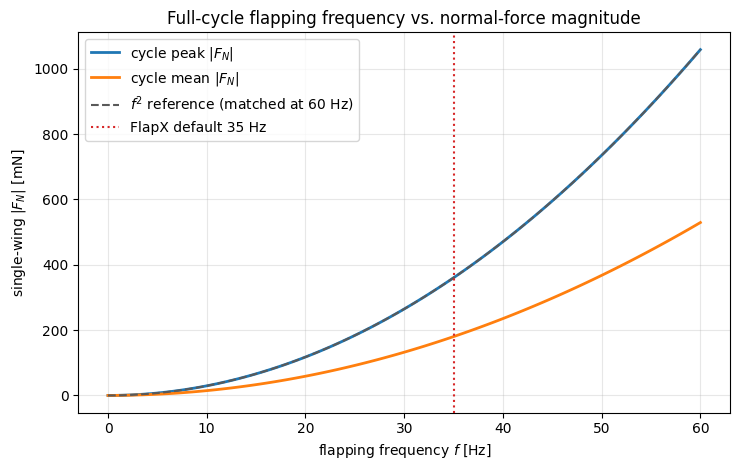

In [119]:
frequency_sweep_hz = np.linspace(0.0, 60.0, 121)
phase = np.linspace(0.0, 2*np.pi, 361, endpoint=False)
force_peak_mN, force_cycle_mean_mN = [], []
for f_hz in frequency_sweep_hz:
    force_over_cycle = []
    for ph in phase:
        row = controlled_left_aero(
            psi=stroke_amplitude*np.sin(ph),
            psi_dot=2*np.pi*f_hz*stroke_amplitude*np.cos(ph),
        )
        force_over_cycle.append(abs(row['F_N']))
    force_over_cycle = np.asarray(force_over_cycle)
    force_peak_mN.append(1e3*force_over_cycle.max())
    force_cycle_mean_mN.append(1e3*force_over_cycle.mean())
force_peak_mN = np.asarray(force_peak_mN)
force_cycle_mean_mN = np.asarray(force_cycle_mean_mN)
f2_reference = force_peak_mN[-1]*(frequency_sweep_hz/frequency_sweep_hz[-1])**2

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(frequency_sweep_hz, force_peak_mN, lw=2, label='cycle peak $|F_N|$')
ax.plot(frequency_sweep_hz, force_cycle_mean_mN, lw=2, label='cycle mean $|F_N|$')
ax.plot(frequency_sweep_hz, f2_reference, '--', color='0.35',
        label='$f^2$ reference (matched at 60 Hz)')
ax.axvline(baseline_frequency_hz, color='C3', ls=':',
           label=f'FlapX default {baseline_frequency_hz:g} Hz')
ax.set(xlabel='flapping frequency $f$ [Hz]', ylabel='single-wing $|F_N|$ [mN]',
       title='Full-cycle flapping frequency vs. normal-force magnitude')
ax.grid(True, alpha=.3); ax.legend(); plt.tight_layout();